# Gambeta : ce que les données disent des 5 grands championnats européens

**Auteur :** Cheikh Mouhamadou Habib FALL · [github.com/habibfl](https://github.com/habibfl)

Ce notebook analyse **5 saisons (2021-22 à 2025-26)** des cinq grands championnats européens (Premier League, Liga, Serie A, Bundesliga, Ligue 1) à partir de données collectées par le projet Gambeta.

**Sources**
- **FBref** (via la bibliothèque `soccerdata`) : résultats de tous les matchs, classements, minutes, tirs, cartons.
- **Understat** : buts attendus (xG), passes décisives attendues (xA) et indicateurs d'implication de chaque joueur (saison 2025-26).

**Les cinq questions**
1. Les championnats ont-ils changé en 5 saisons (buts, avantage du terrain) ?
2. Où la course au titre est-elle la plus disputée ?
3. Le classement reflète-t-il vraiment le niveau des équipes, ou y a-t-il une part de chance ?
4. Quels joueurs marquent plus (ou moins) que la qualité de leurs occasions ne le laissait prévoir ?
5. Peut-on regrouper automatiquement les joueurs en grands profils de jeu ?

> **xG (expected goals)** : probabilité qu'un tir se transforme en but, estimée à partir de milliers de tirs similaires (distance, angle, type d'action). Un joueur à 10 xG « aurait dû » marquer environ 10 buts avec ses occasions.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from adjustText import adjust_text
from sklearn.preprocessing import StandardScaler

import gambeta_data as gd
import gambeta_style as gs

gs.apply()
pd.set_option("display.precision", 2)

## 1. Chargement des données

Les fonctions de chargement sont regroupées dans `gambeta_data.py` (réutilisées par le tableau de bord). Elles lisent directement les CSV de la collecte : il suffit de `pandas` pour tout relancer, sans base de données.

In [2]:
matches = gd.load_matches()
standings = gd.load_standings()
players = gd.load_players("2526")

print(f"Matchs de championnat : {len(matches):,}".replace(",", " "))
print(f"Lignes de classement  : {len(standings)} (équipe x saison)")
print(f"Joueurs 2025-26       : {len(players):,}".replace(",", " "))
print("Saisons :", ", ".join(gd.season_label(s) for s in sorted(matches.season.unique())))

Matchs de championnat : 8 908
Lignes de classement  : 484 (équipe x saison)
Joueurs 2025-26       : 2 775
Saisons : 2021-22, 2022-23, 2023-24, 2024-25, 2025-26


### Contrôle qualité

Avant toute analyse, trois vérifications :
1. chaque club a joué le bon nombre de matchs (2 × (nombre de clubs − 1)) ;
2. les buts des classements correspondent exactement aux buts des matchs ;
3. aucune valeur manquante sur les colonnes clés.

*Ce contrôle a révélé un vrai problème dans une première version : les classements FBref comptaient aussi les barrages de relégation (le 16e de Bundesliga y avait 36 matchs au lieu de 34). Les classements sont donc recalculés à partir des seuls matchs de saison régulière.*

In [3]:
# 1. Chaque club a-t-il joué le bon nombre de matchs ?
check = standings.groupby(["league", "season"]).agg(clubs=("team", "size"), matchs_min=("mp", "min"), matchs_max=("mp", "max"))
check["attendu"] = (check["clubs"] - 1) * 2
check["ok"] = (check["matchs_min"] == check["attendu"]) & (check["matchs_max"] == check["attendu"])
print("Championnats-saisons cohérents :", check["ok"].sum(), "/", len(check))
print(check[~check["ok"]])

# 2. Le classement recalculé à partir des matchs colle-t-il aux matchs eux-mêmes ?
buts_matchs = matches.groupby(["league", "season"])["total_goals"].sum()
buts_classement = standings.groupby(["league", "season"])["gf"].sum()
print("Écart total buts (matchs - classements) :", int((buts_matchs - buts_classement).abs().sum()))

# 3. Valeurs manquantes côté joueurs
print("Valeurs manquantes (xG, minutes) :", int(players[["xg", "minutes"]].isna().sum().sum()))

Championnats-saisons cohérents : 25 / 25
Empty DataFrame
Columns: [clubs, matchs_min, matchs_max, attendu, ok]
Index: []
Écart total buts (matchs - classements) : 0
Valeurs manquantes (xG, minutes) : 0


## 2. Question 1 : les championnats ont-ils changé en 5 saisons ?

In [4]:
per_season = (
    matches.groupby(["league", "season"])
    .agg(buts_par_match=("total_goals", "mean"),
         victoires_domicile=("result", lambda r: (r == "Domicile").mean()),
         nuls=("result", lambda r: (r == "Nul").mean()),
         victoires_exterieur=("result", lambda r: (r == "Extérieur").mean()))
    .reset_index()
)
per_season.pivot(index="season", columns="league", values="buts_par_match").round(2)

league,Bundesliga,Liga,Ligue 1,Premier League,Serie A
season,,,,,
2122,3.12,2.50,2.81,2.82,2.87
2223,3.17,2.51,2.81,2.85,2.56
2324,3.22,2.64,2.70,3.28,2.61
2425,3.13,2.62,2.98,2.93,2.56
2526,3.24,2.69,2.82,2.75,2.43


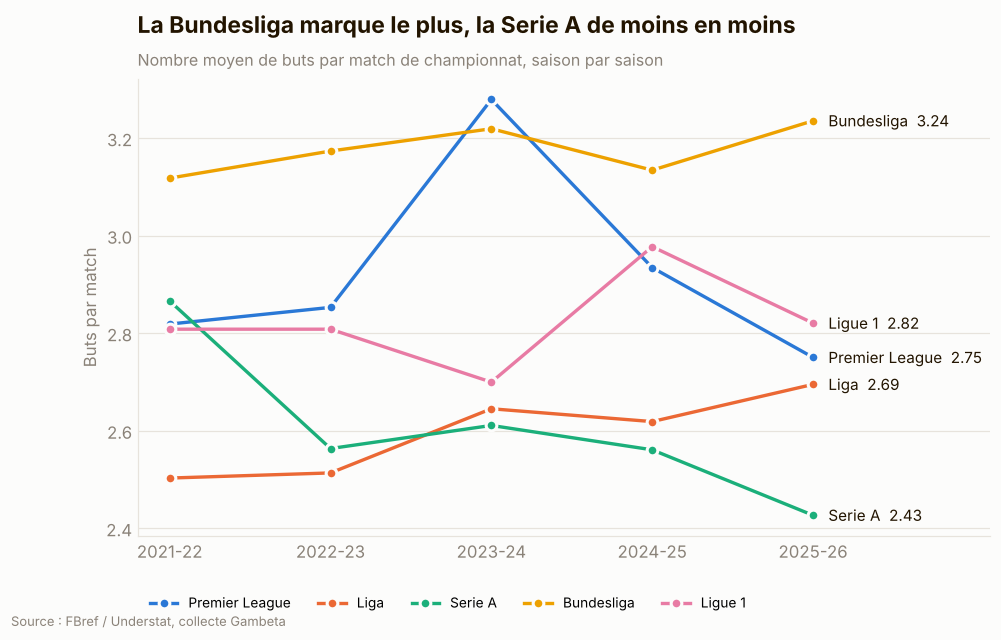

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.4))
seasons = sorted(per_season.season.unique())
x = range(len(seasons))
for league, color in gs.LEAGUE_COLORS.items():
    serie = per_season[per_season.league == league].set_index("season").loc[seasons, "buts_par_match"]
    ax.plot(x, serie.values, color=color, linewidth=2.2, marker="o", markersize=7,
            markeredgecolor=gs.SURFACE, markeredgewidth=2, label=league, zorder=3)
    ax.annotate(f"{league}  {serie.values[-1]:.2f}", (len(seasons) - 1, serie.values[-1]),
                xytext=(10, 0), textcoords="offset points", va="center", color=gs.INK, fontsize=10)
ax.set_xticks(list(x), [gd.season_label(s) for s in seasons])
ax.set_xlim(-0.2, len(seasons) - 1 + 1.1)
ax.set_ylabel("Buts par match")
ax.grid(axis="x", visible=False)
ax.set_title("La Bundesliga marque le plus, la Serie A de moins en moins")
gs.subtitle(ax, "Nombre moyen de buts par match de championnat, saison par saison")
ax.legend(loc="upper left", ncol=5, fontsize=9, bbox_to_anchor=(0, -0.1))
gs.source(fig)
gs.save(fig, "01_buts_par_match")
plt.show()

result          Domicile   Nul  Extérieur
league                                   
Premier League      44.2  23.9       31.9
Liga                45.7  26.2       28.1
Serie A             40.4  27.2       32.4
Bundesliga          44.1  24.9       31.0
Ligue 1             43.4  24.6       32.0


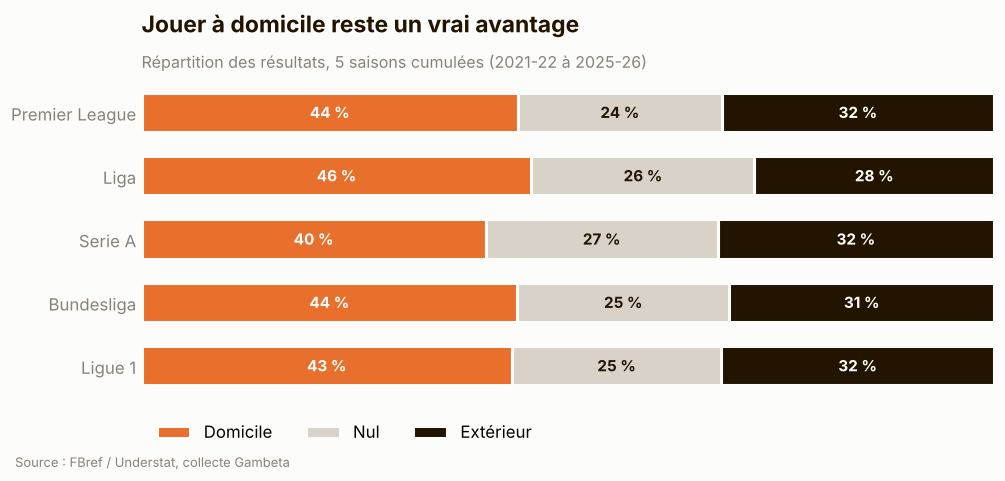

In [6]:
home = matches.groupby("league")["result"].value_counts(normalize=True).unstack()[["Domicile", "Nul", "Extérieur"]]
home = home.loc[list(gs.LEAGUE_COLORS)]
print((home * 100).round(1))

fig, ax = plt.subplots(figsize=(10, 3.8))
left = np.zeros(len(home))
shades = {"Domicile": gs.CORAL, "Nul": "#d9d2c8", "Extérieur": gs.INK}
for col in home.columns:
    ax.barh(home.index, home[col] * 100, left=left, color=shades[col], edgecolor=gs.SURFACE, linewidth=2, height=0.62, label=col)
    for i, v in enumerate(home[col]):
        ax.text(left[i] + v * 50, i, f"{v*100:.0f} %", ha="center", va="center",
                color="white" if col != "Nul" else gs.INK, fontsize=10, fontweight="bold")
    left += home[col].values * 100
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_title("Jouer à domicile reste un vrai avantage")
gs.subtitle(ax, "Répartition des résultats, 5 saisons cumulées (2021-22 à 2025-26)")
ax.legend(loc="upper left", ncol=3, bbox_to_anchor=(0, -0.02))
gs.source(fig)
gs.save(fig, "02_avantage_domicile")
plt.show()

### Ce qu'il faut retenir

- **La Bundesliga est le championnat le plus prolifique** : plus de 3,1 buts par match chaque saison, et en tête 4 saisons sur 5 (seule la Premier League 2023-24, à 3,28, a fait mieux).
- **La Serie A marque de moins en moins** : de 2,87 buts par match en 2021-22 à 2,43 en 2025-26, soit 15 % de buts en moins. C'est le championnat le plus fermé en 2025-26.
- **La Liga est passée de 2,50 à 2,69 buts par match**, mais reste sous la Bundesliga, la Ligue 1 et la Premier League.
- **L'avantage du terrain existe partout** : les équipes à domicile gagnent 40 à 46 % de leurs matchs, contre 28 à 32 % à l'extérieur. Il est le plus marqué en **Liga** (46 % contre 28 %) et le plus faible en **Serie A**, qui est aussi le championnat avec le plus de nuls (27 %).

## 3. Question 2 : où la course au titre est-elle la plus disputée ?

Indicateur choisi : **l'écart de points entre le champion et son dauphin**. Plus il est faible, plus la fin de saison a été serrée.

In [7]:
def resume(t):
    t = t.sort_values("rank")
    return pd.Series({"champion": t.team.iloc[0], "points_champion": t.pts.iloc[0],
                      "ecart_avec_2e": t.pts.iloc[0] - t.pts.iloc[1],
                      "ecart_type_points": t.pts.std()})

titles = standings.groupby(["league", "season"]).apply(resume, include_groups=False).reset_index()
titles.pivot(index="league", columns="season", values="champion")

season,2122,2223,2324,2425,2526
league,,,,,
Bundesliga,Bayern Munich,Bayern Munich,Leverkusen,Bayern Munich,Bayern Munich
Liga,Real Madrid,Barcelona,Real Madrid,Barcelona,Barcelona
Ligue 1,PSG,PSG,PSG,PSG,PSG
Premier League,Manchester City,Manchester City,Manchester City,Liverpool,Arsenal
Serie A,Milan,Napoli,Inter,Napoli,Inter


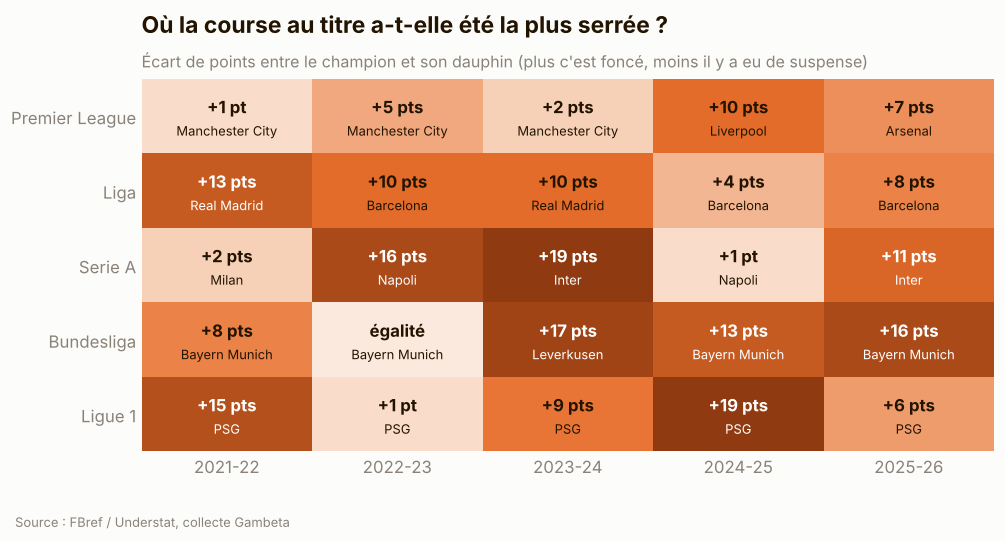

                ecart_moyen  titres_differents
league                                        
Bundesliga             10.8                  2
Liga                    9.0                  2
Ligue 1                10.0                  1
Premier League          5.0                  3
Serie A                 9.8                  3


In [8]:
gap = titles.pivot(index="league", columns="season", values="ecart_avec_2e").loc[list(gs.LEAGUE_COLORS)]
champ = titles.pivot(index="league", columns="season", values="champion").loc[gap.index]

fig, ax = plt.subplots(figsize=(10, 4.4))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("coral", ["#fbe9dd", gs.CORAL, "#8f3a10"])
im = ax.imshow(gap.values, cmap=cmap, aspect="auto", vmin=0, vmax=gap.values.max())
for i in range(gap.shape[0]):
    for j in range(gap.shape[1]):
        v = gap.values[i, j]
        color = "white" if v > gap.values.max() * 0.55 else gs.INK
        label = "égalité" if v == 0 else f"+{int(v)} pt{'s' if v > 1 else ''}"
        ax.text(j, i - 0.12, label, ha="center", va="center", fontsize=11, fontweight="bold", color=color)
        ax.text(j, i + 0.2, champ.values[i, j], ha="center", va="center", fontsize=8.5, color=color)
ax.set_xticks(range(gap.shape[1]), [gd.season_label(s) for s in gap.columns])
ax.set_yticks(range(gap.shape[0]), gap.index)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Où la course au titre a-t-elle été la plus serrée ?")
gs.subtitle(ax, "Écart de points entre le champion et son dauphin (plus c'est foncé, moins il y a eu de suspense)")
gs.source(fig)
gs.save(fig, "03_ecart_champion")
plt.show()

print(titles.groupby("league").agg(ecart_moyen=("ecart_avec_2e", "mean"), titres_differents=("champion", "nunique")).round(1))

### Ce qu'il faut retenir

- **La Premier League est la plus disputée** : 5 points d'écart en moyenne entre le 1er et le 2e, et 3 champions différents en 5 saisons (Manchester City ×3, Liverpool, Arsenal). Deux titres se sont joués à 1 et 2 points.
- **La Ligue 1 est la moins ouverte** : le PSG a gagné les 5 titres. La Bundesliga suit : 4 titres sur 5 pour le Bayern, avec une seule exception, Leverkusen en 2023-24 (+17 points).
- **La Serie A alterne** entre fins de saison très serrées (Milan à +2 en 2021-22, Naples à +1 en 2024-25) et cavaliers seuls (Inter à +19 en 2023-24).
- La fin de saison la plus serrée de la période : **Bundesliga 2022-23**, où le Bayern et Dortmund ont fini à égalité de points (71). Le Bayern a été sacré à la différence de buts.

## 4. Question 3 : le classement reflète-t-il le vrai niveau des équipes ?

La **différence de buts** (buts marqués − buts encaissés) mesure la supériorité d'une équipe sur l'ensemble de ses matchs. On modélise les points par match à partir de la différence de buts par match (régression linéaire sur les 484 équipes-saisons), puis on regarde quelles équipes s'écartent le plus de cette tendance.

In [9]:
slope, intercept = np.polyfit(standings.gd_per_match, standings.pts_per_match, 1)
r2 = np.corrcoef(standings.gd_per_match, standings.pts_per_match)[0, 1] ** 2
standings["pts_attendus"] = (intercept + slope * standings.gd_per_match) * standings.mp
standings["ecart_points"] = standings.pts - standings.pts_attendus
print(f"Points par match = {intercept:.2f} + {slope:.2f} x (différence de buts par match)   R² = {r2:.2f}")

cols = ["league", "season", "team", "rank", "pts", "gd", "pts_attendus", "ecart_points"]
print("\nPlus de points que leur différence de buts ne le laissait prévoir :")
display(standings.sort_values("ecart_points", ascending=False)[cols].head(8).round(1))
print("Moins de points que prévu :")
display(standings.sort_values("ecart_points")[cols].head(8).round(1))

Points par match = 1.37 + 0.64 x (différence de buts par match)   R² = 0.93

Plus de points que leur différence de buts ne le laissait prévoir :


,league,season,team,rank,pts,gd,pts_attendus,ecart_points
306,Premier League,2223,Manchester Utd,3,75,15,61.8,13.2
58,Bundesliga,2425,Freiburg,5,55,-4,44.1,10.9
131,Liga,2324,Barcelona,2,85,35,74.5,10.5
235,Ligue 1,2324,Lyon,6,53,-6,42.9,10.1
465,Serie A,2526,Napoli,2,76,22,66.2,9.8
384,Serie A,2122,Milan,1,86,38,76.5,9.5
300,Premier League,2122,Leeds United,17,38,-37,28.5,9.5
444,Serie A,2425,Napoli,1,82,32,72.6,9.4


Moins de points que prévu :


,league,season,team,rank,pts,gd,pts_attendus,ecart_points
360,Premier League,2425,Tottenham,17,38,-1,51.5,-13.5
194,Ligue 1,2122,Rennes,5,66,42,79.0,-13.0
72,Bundesliga,2526,Bayern Munich,1,89,86,101.6,-12.6
3,Bundesliga,2122,RB Leipzig,4,58,35,69.0,-11.0
148,Liga,2324,Almería,19,21,-32,31.7,-10.7
18,Bundesliga,2223,Bayern Munich,1,71,54,81.2,-10.2
96,Liga,2122,Villarreal,7,59,26,68.8,-9.8
123,Liga,2223,Valencia,14,42,-3,50.3,-8.3


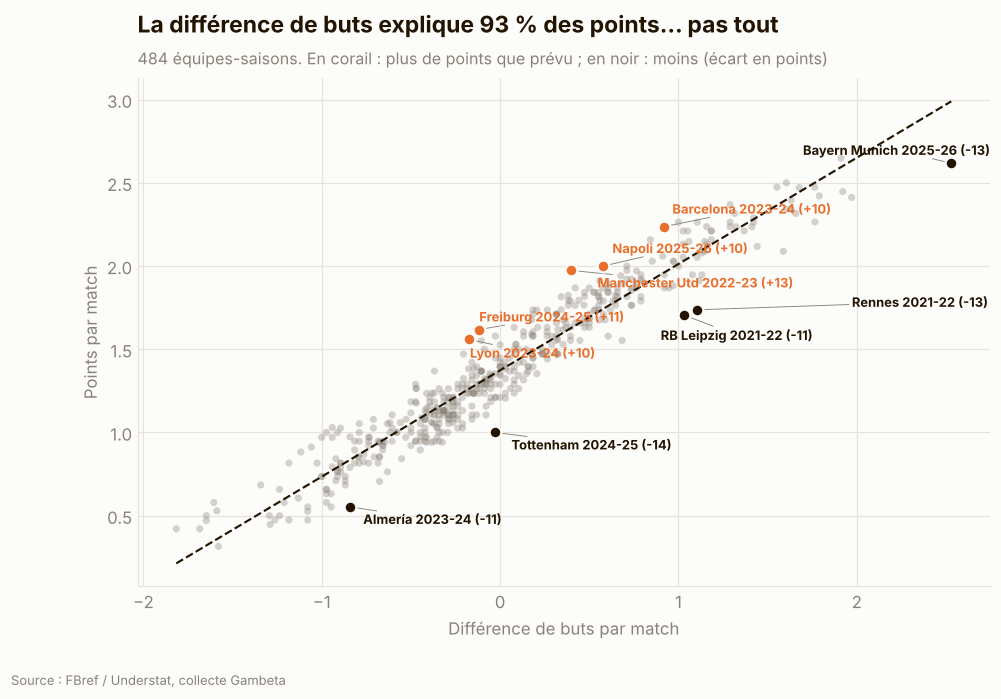

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(standings.gd_per_match, standings.pts_per_match, s=22, color=gs.MUTED, alpha=0.35, edgecolor="none", zorder=2)
xs = np.linspace(standings.gd_per_match.min(), standings.gd_per_match.max(), 50)
ax.plot(xs, intercept + slope * xs, color=gs.INK, linewidth=1.4, linestyle="--", zorder=3)

lucky = standings.nlargest(5, "ecart_points")
unlucky = standings.nsmallest(5, "ecart_points")
texts = []
for frame, color in [(lucky, gs.CORAL), (unlucky, gs.INK)]:
    ax.scatter(frame.gd_per_match, frame.pts_per_match, s=60, color=color, edgecolor=gs.SURFACE, linewidth=1.5, zorder=4)
    for _, r in frame.iterrows():
        texts.append(ax.text(r.gd_per_match, r.pts_per_match, f"{r.team} {gd.season_label(r.season)} ({r.ecart_points:+.0f})",
                             fontsize=8.5, color=color, fontweight="bold", zorder=5))
adjust_text(texts, ax=ax, expand=(1.3, 1.6), arrowprops=dict(arrowstyle="-", color=gs.MUTED, lw=0.6))
ax.set_xlabel("Différence de buts par match")
ax.set_ylabel("Points par match")
ax.set_title("La différence de buts explique 93 % des points... pas tout")
gs.subtitle(ax, f"{len(standings)} équipes-saisons. En corail : plus de points que prévu ; en noir : moins (écart en points)")
gs.source(fig)
gs.save(fig, "04_points_vs_difference_de_buts")
plt.show()

### Ces écarts sont-ils du talent ou de la chance ?

Si gagner des points « en plus » était une compétence (savoir gagner les matchs serrés), les mêmes équipes le referaient d'une saison à l'autre. Vérifions.

In [11]:
# Les équipes "chanceuses" le restent-elles la saison suivante ?
next_season = {"2122": "2223", "2223": "2324", "2324": "2425", "2425": "2526"}
standings["saison_suivante"] = standings.season.map(next_season)
paired = standings.merge(
    standings[["league", "team", "season", "ecart_points", "pts", "rank"]],
    left_on=["league", "team", "saison_suivante"], right_on=["league", "team", "season"], suffixes=("", "_n+1"),
)
print(f"{len(paired)} équipes présentes deux saisons de suite dans le même championnat")
print(f"Corrélation de l'écart d'une saison à l'autre : {np.corrcoef(paired.ecart_points, paired['ecart_points_n+1'])[0, 1]:.2f}")
print(f"(à comparer : corrélation des points d'une saison à l'autre : {np.corrcoef(paired.pts, paired['pts_n+1'])[0, 1]:.2f})")

groups = {"Chanceuses (+6 pts ou plus)": paired.ecart_points >= 6, "Malchanceuses (-6 pts ou moins)": paired.ecart_points <= -6}
summary = pd.DataFrame({
    name: {"équipes": int(mask.sum()),
           "écart saison N": paired.loc[mask, "ecart_points"].mean(),
           "écart saison N+1": paired.loc[mask, "ecart_points_n+1"].mean(),
           "évolution des points": (paired.loc[mask, "pts_n+1"] - paired.loc[mask, "pts"]).mean()}
    for name, mask in groups.items()
}).T
summary.round(1)

331 équipes présentes deux saisons de suite dans le même championnat
Corrélation de l'écart d'une saison à l'autre : 0.21
(à comparer : corrélation des points d'une saison à l'autre : 0.70)


,équipes,écart saison N,écart saison N+1,évolution des points
Chanceuses (+6 pts ou plus),33.0,8.2,2.2,-6.1
Malchanceuses (-6 pts ou moins),23.0,-8.1,-1.3,5.2


### Ce qu'il faut retenir

- **La différence de buts explique 93 % des écarts de points** (R² = 0,93) : une différence de +1 but par match vaut environ 0,64 point par match en plus.
- Les plus gros écarts : **Manchester United 2022-23** a fini 3e avec 75 points pour seulement +15 de différence de buts (13 points de plus que prévu). **Tottenham 2024-25** a fini 17e avec 38 points pour une différence de buts quasi nulle (−1), soit 14 points de moins que prévu.
- **Ces écarts ne se répètent presque pas** : la corrélation de l'écart d'une saison à l'autre n'est que de 0,21, contre 0,70 pour les points eux-mêmes. Les 33 équipes « chanceuses » (au moins 6 points de plus que prévu) **perdent en moyenne 6 points la saison suivante**, et les 23 équipes « malchanceuses » **en regagnent 5**. Manchester United, par exemple, est passé de 75 points (3e) à 60 points (8e).
- **Conclusion pour un analyste** : la différence de buts prédit mieux la saison suivante que le classement. Une équipe très au-dessus de sa tendance doit être regardée avec prudence.
- *Limite* : pour les équipes ultra-dominantes (Bayern 2025-26, +86 de différence de buts), le modèle linéaire surestime les points attendus. Gagner 6-0 ne rapporte pas plus de points que 1-0 : leur écart négatif n'est pas de la malchance.

## 5. Question 4 : qui marque plus (ou moins) que ses occasions ne le valent ?

Saison 2025-26 uniquement (les xG des saisons précédentes n'ont pas pu être collectés : Understat était en maintenance au moment de la collecte). On ne garde que les joueurs de champ ayant joué au moins 900 minutes (10 matchs complets), pour éviter les conclusions sur quelques apparitions.

In [12]:
total = players[["goals", "xg", "np_goals", "np_xg"]].sum()
print(f"Buts marqués : {total.goals:.0f}  |  xG : {total.xg:.0f}  ->  {total.goals / total.xg - 1:+.1%}")
print(f"Hors penalty : {total.np_goals:.0f} buts pour {total.np_xg:.0f} npxG  ->  {total.np_goals / total.np_xg - 1:+.1%}")

by_league = players.groupby("league")[["goals", "xg"]].sum()
by_league["ecart"] = by_league.goals / by_league.xg - 1
print((by_league.sort_values("ecart")).round(2))

regulars = players[(players.minutes >= 900) & (players.position_code != "GK")].copy()
print(f"\nJoueurs de champ avec au moins 900 minutes : {len(regulars)}")
print(f"Corrélation buts / xG : {np.corrcoef(regulars.goals, regulars.xg)[0, 1]:.2f}")
cols = ["player", "team", "league", "goals", "xg", "goals_minus_xg", "shots"]
display(regulars.nlargest(10, "goals_minus_xg")[cols].round(1))
display(regulars.nsmallest(10, "goals_minus_xg")[cols].round(1))

Buts marqués : 4716  |  xG : 5423  ->  -13.0%
Hors penalty : 4289 buts pour 5006 npxG  ->  -14.3%
                goals       xg  ecart
league                               
Serie A           900  1077.53  -0.16
Premier League   1004  1183.88  -0.15
Liga             1003  1158.02  -0.13
Ligue 1           839   944.31  -0.11
Bundesliga        970  1059.54  -0.08

Joueurs de champ avec au moins 900 minutes : 1471
Corrélation buts / xG : 0.92


,player,team,league,goals,xg,goals_minus_xg,shots
1789,Harry Kane,Bayern Munich,Bundesliga,36,29.6,6.4,119
2230,Esteban Lepaul,Angers,Ligue 1,21,15.7,5.3,87
1109,Alberto Moleiro,Villarreal,Liga,10,5.6,4.4,46
1132,Tajon Buchanan,Villarreal,Liga,7,2.7,4.3,27
249,Harry Wilson,Fulham,Premier League,10,5.8,4.2,78
61,Antoine Semenyo,Bournemouth,Premier League,17,12.8,4.2,83
67,Eli Junior Kroupi,Bournemouth,Premier League,13,8.8,4.2,52
1262,Martin Baturina,Como,Serie A,6,1.9,4.1,28
938,Pablo Fornals,Real Betis,Liga,9,4.9,4.1,43
2089,Yan Diomande,RasenBallsport Leipzig,Bundesliga,12,8.0,4.0,53


,player,team,league,goals,xg,goals_minus_xg,shots
1324,Moise Kean,Fiorentina,Serie A,8,15.4,-7.4,98
2082,Rômulo,RasenBallsport Leipzig,Bundesliga,9,15.9,-6.9,63
2320,Issa Soumaré,Le Havre,Ligue 1,8,14.2,-6.2,77
2117,Andrej Ilic,Union Berlin,Bundesliga,5,11.1,-6.1,71
69,Evanilson,Bournemouth,Premier League,6,11.8,-5.8,72
1184,Nikola Krstovic,Atalanta,Serie A,10,15.7,-5.7,99
577,Iñaki Williams,Athletic Club,Liga,3,8.7,-5.7,57
1745,Phillip Tietz,Augsburg,Bundesliga,6,11.6,-5.6,51
65,David Brooks,Bournemouth,Premier League,1,6.5,-5.5,48
2485,Pierre-Emerick Aubameyang,Marseille,Ligue 1,10,15.5,-5.5,60


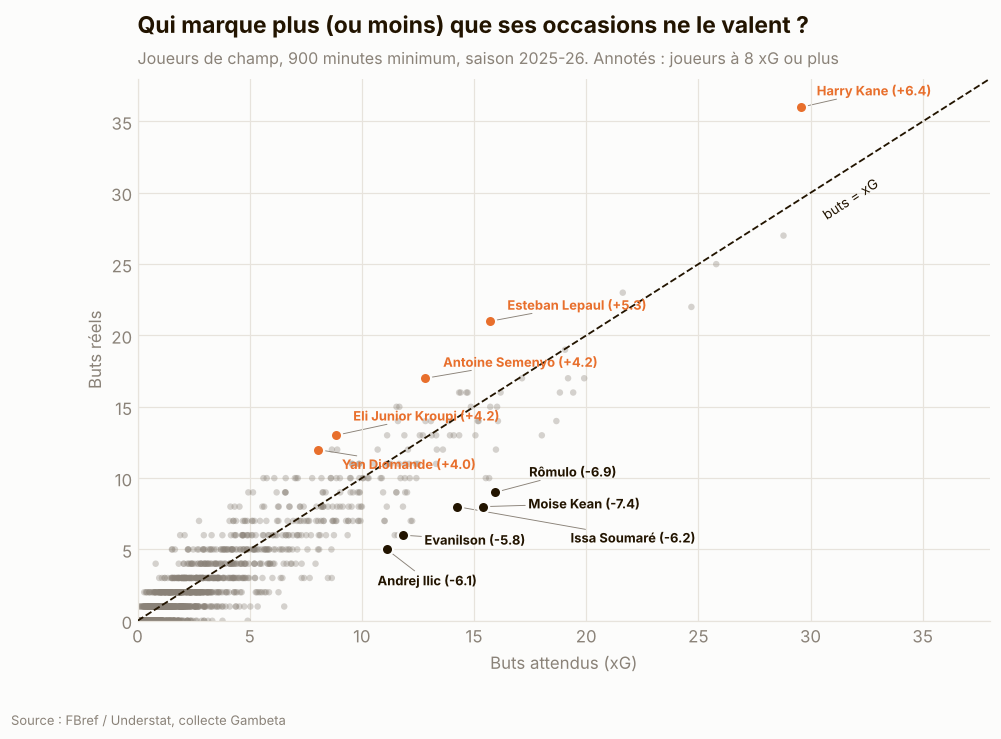

In [13]:
fig, ax = plt.subplots(figsize=(10, 6.4))
ax.scatter(regulars.xg, regulars.goals, s=18, color=gs.MUTED, alpha=0.35, edgecolor="none", zorder=2)
lim = max(regulars.xg.max(), regulars.goals.max()) + 2
ax.plot([0, lim], [0, lim], color=gs.INK, linewidth=1.2, linestyle="--", zorder=3)
ax.text(lim * 0.80, lim * 0.74, "buts = xG", color=gs.INK, fontsize=9, rotation=33)

top = regulars[regulars.xg >= 8]
over = top.nlargest(5, "goals_minus_xg")
under = top.nsmallest(5, "goals_minus_xg")
texts = []
for frame, color in [(over, gs.CORAL), (under, gs.INK)]:
    ax.scatter(frame.xg, frame.goals, s=55, color=color, edgecolor=gs.SURFACE, linewidth=1.5, zorder=4)
    for _, r in frame.iterrows():
        texts.append(ax.text(r.xg, r.goals, f"{r.player} ({r.goals_minus_xg:+.1f})", fontsize=8.5, color=color,
                             fontweight="bold", zorder=5))
adjust_text(texts, ax=ax, expand=(1.3, 1.8), arrowprops=dict(arrowstyle="-", color=gs.MUTED, lw=0.6))
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel("Buts attendus (xG)")
ax.set_ylabel("Buts réels")
ax.set_title("Qui marque plus (ou moins) que ses occasions ne le valent ?")
gs.subtitle(ax, "Joueurs de champ, 900 minutes minimum, saison 2025-26. Annotés : joueurs à 8 xG ou plus")
gs.source(fig)
gs.save(fig, "05_finisseurs_buts_vs_xg")
plt.show()

### Ce qu'il faut retenir

- **Les xG prédisent très bien les buts** sur une saison : corrélation de 0,92 entre buts réels et buts attendus chez les 1 471 joueurs réguliers.
- **Harry Kane est le finisseur de la saison** : 36 buts pour 29,6 xG (+6,4). Derrière lui, Esteban Lepaul (Angers, +5,3) et Antoine Semenyo (Bournemouth, +4,2).
- **Moise Kean (Fiorentina) est le plus en dessous** : 8 buts pour 15,4 xG (−7,4), suivi de Rômulo (Leipzig, −6,9) et d'Issa Soumaré (Le Havre, −6,2). Ils se créent des occasions mais les convertissent mal cette saison.
- **Un constat global surprenant** : sur les 5 championnats, il y a eu **13 % de buts en moins que les xG** (4 716 buts pour 5 423 xG). Tous les championnats sont concernés, de −8 % (Bundesliga) à −16 % (Serie A). Habituellement, buts et xG s'équilibrent sur une saison entière : soit les gardiens ont été exceptionnels, soit le modèle d'Understat surestime les occasions cette saison. C'est une piste à creuser quand les saisons précédentes seront disponibles.
- *Limite* : une seule saison, c'est peu. La finition d'un joueur ne se juge vraiment que sur plusieurs saisons.

## 6. Question 5 : peut-on regrouper les joueurs en profils de jeu ?

Méthode : **K-means**, un algorithme de clustering (apprentissage non supervisé) qui regroupe les joueurs aux statistiques proches.

- 6 indicateurs par 90 minutes : danger (npxG), création (xA), tirs, passes clés, implication dans les actions menant à un tir (xGChain) et participation à la construction (xGBuildup).
- Les indicateurs sont standardisés (moyenne 0, écart-type 1) pour qu'aucun ne domine les autres à cause de son échelle.
- Même échantillon qu'à la question 4 : 1 471 joueurs de champ, 900 minutes minimum.

In [14]:
features = {"np_xg_90": "Danger (npxG)", "xa_90": "Création (xA)", "shots_90": "Tirs",
            "key_passes_90": "Passes clés", "xg_chain_90": "Implication (xGChain)", "xg_buildup_90": "Construction (xGBuildup)"}
X = StandardScaler().fit_transform(regulars[list(features)])

scores = {k: silhouette_score(X, KMeans(k, n_init=20, random_state=0).fit_predict(X)) for k in range(3, 8)}
print("Score de silhouette selon le nombre de groupes :", {k: round(v, 3) for k, v in scores.items()})

kmeans = KMeans(5, n_init=20, random_state=0).fit(X)
regulars["groupe"] = kmeans.labels_
profile = pd.DataFrame(kmeans.cluster_centers_, columns=list(features.values()))
profile["joueurs"] = regulars.groupe.value_counts().sort_index().values
profile.round(2)

Score de silhouette selon le nombre de groupes : {3: 0.386, 4: 0.341, 5: 0.326, 6: 0.275, 7: 0.272}


,Danger (npxG),Création (xA),Tirs,Passes clés,Implication (xGChain),Construction (xGBuildup),joueurs
0,1.65,0.08,1.42,0.01,0.66,-0.70,236
1,-0.49,-0.25,-0.52,-0.23,0.55,1.52,211
2,1.11,2.17,1.40,1.95,2.15,1.28,96
3,-0.57,-0.70,-0.66,-0.72,-0.82,-0.41,602
4,-0.16,0.77,0.13,0.90,0.06,-0.10,326


In [15]:
# Nom de chaque groupe, déduit de son profil moyen (centres ci-dessus, en écarts-types)
def nommer(row):
    if row["Danger (npxG)"] > 1 and row["Création (xA)"] > 1:
        return "Stars offensives complètes"
    if row["Danger (npxG)"] > 0.8:
        return "Finisseurs"
    if row["Construction (xGBuildup)"] > 0.5 and row["Danger (npxG)"] < 0:
        return "Relanceurs / constructeurs"
    if row["Création (xA)"] > 0.2:
        return "Créateurs"
    return "Profils défensifs"

profile["nom"] = profile.apply(nommer, axis=1)
regulars["profil"] = regulars.groupe.map(profile["nom"])
assert profile["nom"].nunique() == 5, profile["nom"].tolist()

for name, grp in regulars.groupby("profil"):
    exemples = grp.sort_values("xg_chain_90", ascending=False).player.head(5).tolist()
    postes = grp.poste.value_counts(normalize=True).mul(100).round().astype(int).to_dict()
    print(f"{name} ({len(grp)} joueurs) : {', '.join(exemples)}  | postes : {postes}")

Créateurs (326 joueurs) : Kamaldeen Sulemana, Valentín Barco, Maghnes Akliouche, Hákon Haraldsson, Malik Tillman  | postes : {'Attaquant': 36, 'Défenseur': 35, 'Milieu': 30}
Finisseurs (236 joueurs) : Robert Lewandowski, Ferrán Torres, Nikola Krstovic, Erling Haaland, Rômulo  | postes : {'Attaquant': 89, 'Milieu': 6, 'Défenseur': 5}
Profils défensifs (602 joueurs) : Ozan Kabak, Pablo Marín, Ainsley Maitland-Niles, Mahdi Camara, Martijn Kaars  | postes : {'Défenseur': 74, 'Milieu': 21, 'Attaquant': 5}
Relanceurs / constructeurs (211 joueurs) : Xaver Schlager, Aleksandar Pavlovic, Amir Murillo, Josip Stanisic, Vitinha  | postes : {'Défenseur': 65, 'Milieu': 34, 'Attaquant': 1}
Stars offensives complètes (96 joueurs) : Michael Olise, Luis Díaz, Lamine Yamal, Harry Kane, Lennart Karl  | postes : {'Attaquant': 64, 'Milieu': 21, 'Défenseur': 16}


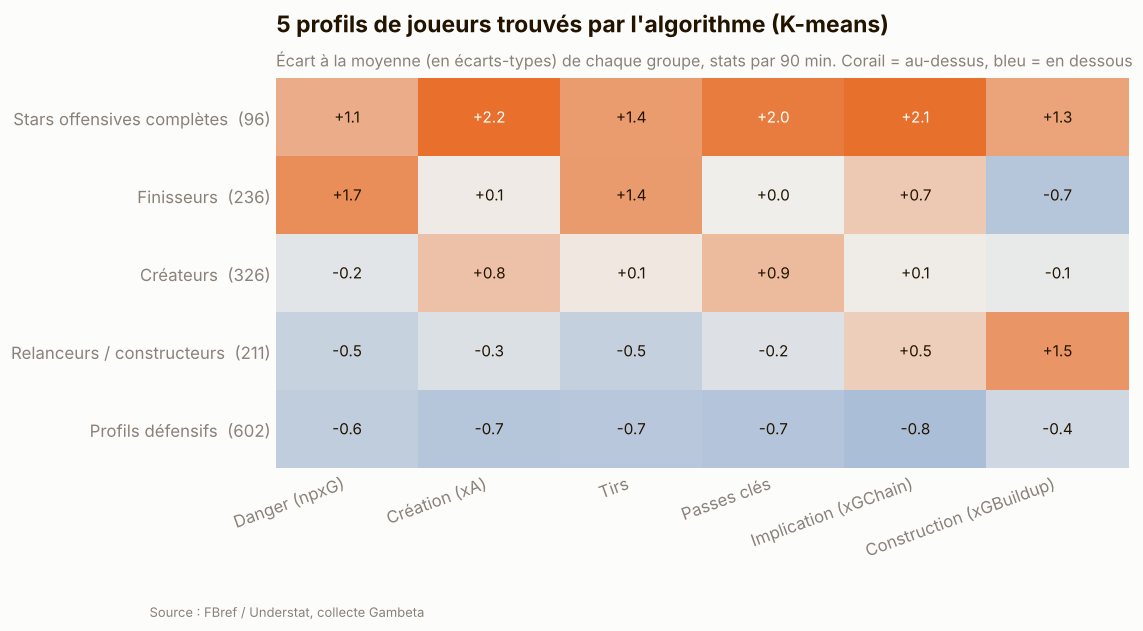

In [16]:
order = ["Stars offensives complètes", "Finisseurs", "Créateurs", "Relanceurs / constructeurs", "Profils défensifs"]
heat = profile.set_index("nom").loc[order, list(features.values())]

fig, ax = plt.subplots(figsize=(10, 4.6))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("div", ["#3d6fb6", "#f0efec", gs.CORAL])
lim = np.abs(heat.values).max()
ax.imshow(heat.values, cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=10, color="white" if abs(v) > lim * 0.8 else gs.INK)
counts = profile.set_index("nom").loc[order, "joueurs"]
ax.set_yticks(range(len(order)), [f"{n}  ({c})" for n, c in zip(order, counts)])
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=20, ha="right")
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("5 profils de joueurs trouvés par l'algorithme (K-means)")
gs.subtitle(ax, "Écart à la moyenne (en écarts-types) de chaque groupe, stats par 90 min. Corail = au-dessus, bleu = en dessous")
gs.source(fig, y=-0.16)
gs.save(fig, "06_profils_joueurs_kmeans")
plt.show()

### Ce qu'il faut retenir

L'algorithme retrouve **5 profils** qui parlent à n'importe quel amateur de football :

| Profil | Joueurs | Signature statistique | Exemples |
|---|---|---|---|
| Stars offensives complètes | 96 | au-dessus de la moyenne partout, surtout en création | Olise, Luis Díaz, Lamine Yamal, Kane |
| Finisseurs | 236 | beaucoup de tirs et de danger, peu de construction | Lewandowski, Haaland, Krstović |
| Créateurs | 326 | passes clés et xA, peu de tirs | Akliouche, Tillman, Haraldsson |
| Relanceurs / constructeurs | 211 | très impliqués dans la construction, peu dans la finition | Vitinha, Koundé, Pavlović |
| Profils défensifs | 602 | peu impliqués offensivement | surtout des défenseurs (74 %) |

- Le score de silhouette (qualité de séparation des groupes) est meilleur avec 3 groupes (0,39) qu'avec 5 (0,33). **5 groupes ont été retenus parce qu'ils sont beaucoup plus faciles à interpréter**, pour une perte de séparation modérée. C'est un compromis assumé, fréquent en clustering.
- Les postes officiels ne suffisent pas : le groupe « Créateurs » mélange attaquants (36 %), défenseurs (35 %, des latéraux offensifs) et milieux (30 %). Le clustering décrit **ce que fait un joueur**, pas où il est placé sur la feuille de match.
- *Limite* : seuls des indicateurs offensifs sont utilisés (ceux d'Understat). Ajouter les actions défensives (tacles, interceptions de FBref) permettrait de mieux distinguer les profils défensifs.

## 7. Conclusion

**Les cinq enseignements principaux**
1. La Bundesliga reste le championnat le plus offensif ; la Serie A s'est refermée (−15 % de buts en 5 saisons).
2. La Premier League est le championnat le plus ouvert pour le titre ; la Ligue 1 le moins (5 titres du PSG sur 5).
3. La différence de buts explique 93 % des points, et ce qui s'en écarte est surtout de la chance : ça ne se répète pas la saison suivante.
4. Les xG prédisent très bien les buts (corrélation 0,92), mais 2025-26 a vu 13 % de buts en moins qu'attendu dans les 5 championnats.
5. Un clustering simple retrouve 5 profils de joueurs cohérents, plus parlants que les postes officiels.

**Limites**
- Les xG ne couvrent qu'une saison (Understat en maintenance au moment de la collecte des saisons précédentes).
- Les indicateurs de possession et de passes (progressions, passes progressives) ne sont pas disponibles via `soccerdata`.
- Le modèle de points est volontairement simple (régression linéaire) pour rester lisible.

**Pistes pour aller plus loin**
- Compléter les xG 2021-22 à 2024-25 et vérifier si la finition d'un joueur se répète d'une saison à l'autre.
- Construire un modèle de points attendus match par match (xPts) à partir des xG de chaque match.
- Enrichir le clustering avec les statistiques défensives.

*Les figures de ce notebook sont exportées dans `analysis/figures/` et reprises dans le README du projet.*